# Cleaning the Bahrain Grand Prix 2023

## Loading the data

In [2]:
import fastf1 
import pandas as pd

fastf1.Cache.configure(cache_dir='cache')

session = fastf1.get_session(2023, 'Bahrain', 'R')
session.load(telemetry=False, weather=False, messages=False)

laps = session.laps
print('Laps at the start:', len(laps)) 


core           INFO 	Loading data for Bahrain Grand Prix - Race [v3.9.0]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core           INFO 	Finished loading data for 20 drivers: ['1', '11', '14', '55', '44', '18', '63', '77', '10', '23', '22', '2', '20', '21', '27', '24', '4', '31', '16', '81']


Laps at the start: 1056


## Cleaning part 1: pit laps, lap 1 and bad data

In [3]:
no_pits = laps.pick_wo_box()
print('Laps left:', len(no_pits), 'Removed', len(laps) - len(no_pits))

Laps left: 954 Removed 102


In [4]:
no_lap1 = no_pits[no_pits['LapNumber'] > 1]
print('Laps left:', len(no_lap1), 'Removed', len(no_pits) - len(no_lap1))

Laps left: 934 Removed 20


In [5]:
accurate = no_lap1[no_lap1['IsAccurate'] == True]
print('Laps left:', len(accurate), 'Removed', len(no_lap1) - len(accurate))

Laps left: 914 Removed 20


In [6]:
inaccurate = no_lap1[no_lap1['IsAccurate'] == False]
inaccurate[['Driver', 'LapNumber', 'LapTime', 'TrackStatus']]

,Driver,LapNumber,LapTime,TrackStatus
40,VER,41.0,0 days 00:02:00.495000,126
41,VER,42.0,0 days 00:01:44.824000,671
154,PER,41.0,0 days 00:02:03.522000,126
155,PER,42.0,0 days 00:01:39.657000,671
211,ALO,41.0,0 days 00:02:06.713000,2671
267,LEC,40.0,NaT,126
307,STR,40.0,0 days 00:01:37.916000,126
308,STR,41.0,0 days 00:02:06.809000,671
476,DEV,40.0,0 days 00:01:53.544000,126
477,DEV,41.0,0 days 00:01:54.359000,671


In [7]:
cleaned = accurate[accurate['LapTime'].notna()]
print('Laps left:', len(cleaned), 'Removed', len(accurate) - len(cleaned))

Laps left: 914 Removed 0


In [8]:
funnel = pd.DataFrame({
    'Step': ['Start', 'Remove in-laps and out-laps', 'Remove lap 1', 'Remove inaccurate laps', 'Remove laps with no lap time'],
    'Laps left': [len(laps), len(no_pits), len(no_lap1), len(accurate), len(cleaned)],
    'Laps removed': [0, len(laps) - len(no_pits), len(no_pits) - len(no_lap1), len(no_lap1) - len(accurate), len(accurate) - len(cleaned)],
})
funnel 

,Step,Laps left,Laps removed
0,Start,1056,0
1,Remove in-laps and out-laps,954,102
2,Remove lap 1,934,20
3,Remove inaccurate laps,914,20
4,Remove laps with no lap time,914,0


In [9]:
print('Inaccurate laps in the whole race:', (laps['IsAccurate'] == False).sum())
print('Laps with no lap time in the whole race:', laps['LapTime'].isna().sum())
print(cleaned['TrackStatus'].value_counts())

Inaccurate laps in the whole race: 142
Laps with no lap time in the whole race: 1
TrackStatus
1     889
21     19
12      6
Name: count, dtype: int64


## Cleaning part 2: flags and Safety Cars

In [10]:
print(laps['TrackStatus'].value_counts())
print('Laps with a Safety Car (4):', laps['TrackStatus'].str.contains('4').sum())
print('Laps with a red flag (5):', laps['TrackStatus'].str.contains('5').sum())
print('Laps with a VSC (6):', laps['TrackStatus'].str.contains('6').sum())

TrackStatus
1       979
12       26
21       19
126      14
671      13
2671      5
Name: count, dtype: int64
Laps with a Safety Car (4): 0
Laps with a red flag (5): 0
Laps with a VSC (6): 32


In [11]:
vsc = laps[laps['TrackStatus'].str.contains('6')]
pit_laps = vsc['PitInTime'].notna() | vsc['PitOutTime'].notna()
print('VSC laps:', len(vsc), 'On laps:', sorted(vsc['LapNumber'].astype(int).unique().tolist()))
print('In or out laps:', pit_laps.sum(), 'Other laps:', (~pit_laps).sum())

VSC laps: 32 On laps: [40, 41, 42]
In or out laps: 12 Other laps: 20


In [12]:
green = cleaned.pick_track_status('1')
print('Laps left:', len(green), 'Removed', len(cleaned) - len(green))

Laps left: 889 Removed 25


In [13]:
yellow = cleaned[cleaned['TrackStatus'] !='1']
yellow[['Driver', 'LapNumber', 'LapTime', 'TrackStatus']]

,Driver,LapNumber,LapTime,TrackStatus
1,VER,2.0,0 days 00:01:37.974000,12
58,GAS,2.0,0 days 00:01:40.438000,21
115,PER,2.0,0 days 00:01:38.862000,21
172,ALO,2.0,0 days 00:01:39.792000,21
210,ALO,40.0,0 days 00:01:37.208000,12
229,LEC,2.0,0 days 00:01:38.750000,21
269,STR,2.0,0 days 00:01:39.892000,21
326,SAR,2.0,0 days 00:01:40.467000,21
382,MAG,2.0,0 days 00:01:41.521000,21
438,DEV,2.0,0 days 00:01:41.289000,21


In [14]:
print(yellow['LapNumber'].value_counts())

LapNumber
2.0     20
40.0     3
39.0     2
Name: count, dtype: int64


In [15]:
print(green['TrackStatus'].value_counts())

TrackStatus
1    889
Name: count, dtype: int64


In [16]:
funnel = pd.DataFrame({
    'Step': ['Start', 'Remove in laps and out laps', 'Remove lap 1', 'Remove inaccurate laps', 'Remove laps with no lap time', 'Keep only green flag laps'],
    'Laps left': [len(laps), len(no_pits), len(no_lap1), len(accurate), len(cleaned), len(green)],
    'Laps removed': [0, len(laps) - len(no_pits), len(no_pits) - len(no_lap1), len(no_lap1) - len(accurate), len(accurate) - len(cleaned), len(cleaned) - len(green)],
})
funnel

,Step,Laps left,Laps removed
0,Start,1056,0
1,Remove in laps and out laps,954,102
2,Remove lap 1,934,20
3,Remove inaccurate laps,914,20
4,Remove laps with no lap time,914,0
5,Keep only green flag laps,889,25


In [17]:
laps[(laps['Driver'] == 'VER') & (laps['LapNumber'].isin([40, 41, 42]))][['LapNumber', 'LapTime', 'TrackStatus', 'TyreLife']]

,LapNumber,LapTime,TrackStatus,TyreLife
39,40.0,0 days 00:01:36.942000,1,4.0
40,41.0,0 days 00:02:00.495000,126,5.0
41,42.0,0 days 00:01:44.824000,671,6.0


Verstappen laps left: 49


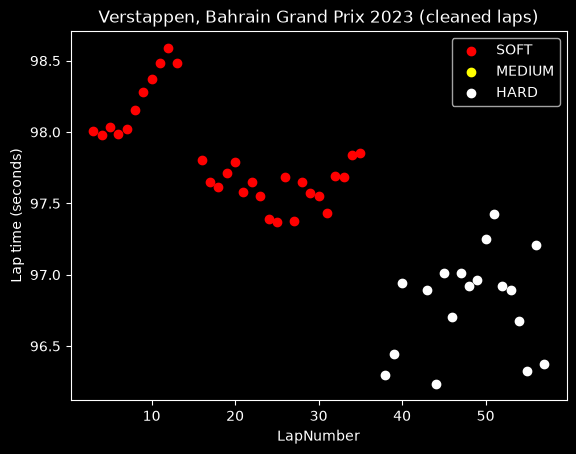

In [18]:
import matplotlib.pyplot as plt
plt.style.use('dark_background')

green = green.copy()
green['LapTimeSeconds'] = green['LapTime'].dt.total_seconds()
ver = green[green['Driver'] == 'VER']
print('Verstappen laps left:', len(ver))

compound_colours = {'SOFT': 'red', 'MEDIUM': 'yellow', 'HARD': 'white'}

for compound, colour in compound_colours.items():
    data = ver[ver['Compound'] == compound]
    plt.scatter(data['LapNumber'], data['LapTimeSeconds'], color = colour, label = compound)

plt.xlabel('LapNumber')
plt.ylabel('Lap time (seconds)')
plt.title('Verstappen, Bahrain Grand Prix 2023 (cleaned laps)')
plt.legend()
plt.savefig('figures/Verstappen_Bahrain_Grand_Prix_2023_cleaned_laps.png', dpi = 300, bbox_inches = 'tight')
plt.show()

In [19]:
print(ver.groupby('Compound')['LapTimeSeconds'].agg(['count', 'min', 'max']))
print('Missing laps:', sorted(set(range(1, int(laps['LapNumber'].max()) + 1)) - set(ver['LapNumber'])))

          count     min     max
Compound                       
HARD         18  96.236  97.427
SOFT         31  97.372  98.591
Missing laps: [1, 2, 14, 15, 36, 37, 41, 42]


In [20]:
green[(green['Driver'] == 'SAI') & (green['LapNumber'] == 45)][['LapNumber', 'LapTime', 'TrackStatus']]

,LapNumber,LapTime,TrackStatus
916,45.0,0 days 00:01:39.561000,1


In [21]:
laps[laps['Driver'] == 'VER'].groupby('Stint')[['LapNumber', 'Compound', 'TyreLife', 'FreshTyre']].first()

,LapNumber,Compound,TyreLife,FreshTyre
Stint,,,,
1.0,1.0,SOFT,4.0,False
2.0,15.0,SOFT,1.0,False
3.0,37.0,HARD,1.0,True


## Cleaning part 3: Traffic

In [22]:
quick = green.pick_quicklaps(1.07)
print('Fastest lap:', green['LapTimeSeconds'].min(), 'Limit:',
round(green['LapTimeSeconds'].min() * 1.07, 3))
print('Laps left:', len(quick), 'Removed', len(green) - len(quick))

Fastest lap: 93.996 Limit: 100.576
Laps left: 798 Removed 91


In [23]:
removed = green[~green.index.isin(quick.index)]
print(removed['Driver'].value_counts().head())

Driver
MAG    12
PIA    10
ZHO     9
SAR     8
DEV     8
Name: count, dtype: int64


In [24]:
median = green.groupby('Driver')['LapTimeSeconds'].transform('median')
print('Laps more than 7% slower than the driver median:',
      (green['LapTimeSeconds'] > median * 1.07).sum())

Laps more than 7% slower than the driver median: 0


In [25]:
order = laps[['Driver', 'LapNumber', 'Position', 'Time']].dropna()

car_ahead = order.copy()
car_ahead['Position'] = car_ahead['Position'] + 1

gaps = order.merge(car_ahead, on = ['LapNumber', 'Position'], suffixes=('', 'Ahead'))
gaps['GapAhead'] = (gaps['Time'] - gaps['TimeAhead']).dt.total_seconds()
gaps.head()

,Driver,LapNumber,Position,Time,DriverAhead,TimeAhead,GapAhead
0,VER,15.0,2.0,0 days 01:27:33.930000,PER,0 days 01:27:22.622000,11.308
1,VER,16.0,2.0,0 days 01:29:11.731000,PER,0 days 01:29:01.392000,10.339
2,VER,17.0,2.0,0 days 01:30:49.379000,PER,0 days 01:30:42.752000,6.627
3,GAS,1.0,19.0,0 days 01:04:26.532000,MAG,0 days 01:04:26.213000,0.319
4,GAS,2.0,18.0,0 days 01:06:06.970000,ZHO,0 days 01:06:06.441000,0.529


In [26]:
green_gaps = green.merge(gaps[['Driver', 'LapNumber', 'DriverAhead', 'GapAhead']], on = ['Driver', 'LapNumber'], how = 'left')
print ('Laps:', len(green_gaps))
print(green_gaps['GapAhead'].describe().round(3))
print('Laps with no car ahead:', green_gaps['GapAhead'].isna().sum())
print(green_gaps[green_gaps['GapAhead'].isna()]['Driver'].value_counts())

Laps: 889
count    840.000
mean       5.781
std        7.072
min        0.010
25%        1.388
50%        3.300
75%        7.944
max       61.118
Name: GapAhead, dtype: float64
Laps with no car ahead: 49
Driver
VER    47
PER     2
Name: count, dtype: int64


In [27]:
for limit in [1.0, 1.5, 2.0]:
    print('Under', limit, 's:', (green_gaps['GapAhead'] < limit).sum())

Under 1.0 s: 134
Under 1.5 s: 229
Under 2.0 s: 315


In [28]:
green_gaps['SlowerThanMedian'] = green_gaps['LapTimeSeconds'] - green_gaps.groupby('Driver')['LapTimeSeconds'].transform('median')
green_gaps['InTraffic'] = green_gaps['GapAhead'] < 1.0
print(green_gaps.groupby('InTraffic')['SlowerThanMedian'].agg(['count', 'mean', 'median']).round(3))

           count   mean  median
InTraffic                      
False        755  0.080  -0.053
True         134  0.899   0.646


In [29]:
print(green_gaps.groupby('InTraffic')['LapNumber'].median())

green_gaps['SlowerThanStintMedian'] = green_gaps['LapTimeSeconds'] - green_gaps.groupby(['Driver', 'Stint'])['LapTimeSeconds'].transform('median')
print(green_gaps.groupby('InTraffic')['SlowerThanStintMedian'].agg(['count', 'mean', 'median']).round(3))

InTraffic
False    30.0
True     12.0
Name: LapNumber, dtype: float64
           count   mean  median
InTraffic                      
False        755  0.031   0.000
True         134 -0.036  -0.016


In [30]:
green_gaps[(green_gaps['Driver'] == 'SAI') & 
           (green_gaps['LapNumber'].between(43, 47))][['LapNumber', 'LapTimeSeconds', 'DriverAhead', 'GapAhead']]

,LapNumber,LapTimeSeconds,DriverAhead,GapAhead
766,43.0,97.294,PER,23.729
767,44.0,97.389,PER,24.140
768,45.0,99.561,ALO,0.988
769,46.0,97.844,ALO,1.745
770,47.0,98.222,ALO,2.641


In [31]:
laps[(laps['Driver'].isin(['SAI', 'ALO'])) & (laps['LapNumber'].between(43, 46))][['Driver', 'LapNumber', 'Position']]

,Driver,LapNumber,Position
213,ALO,43.0,4.0
214,ALO,44.0,4.0
215,ALO,45.0,3.0
216,ALO,46.0,3.0
914,SAI,43.0,3.0
915,SAI,44.0,3.0
916,SAI,45.0,4.0
917,SAI,46.0,4.0


In [33]:
print(green_gaps['SlowerThanStintMedian'].describe().round(3))
green_gaps.sort_values('SlowerThanStintMedian', ascending=False)[['Driver', 'LapNumber', 'LapTimeSeconds', 'SlowerThanStintMedian', 'GapAhead']].head(10).round(3)

count    889.000
mean       0.021
std        0.482
min       -1.525
25%       -0.225
50%        0.000
75%        0.224
max        2.928
Name: SlowerThanStintMedian, dtype: float64


,Driver,LapNumber,LapTimeSeconds,SlowerThanStintMedian,GapAhead
678,NOR,49.0,99.080,2.928,61.118
603,HUL,46.0,99.972,2.666,11.693
325,SAR,56.0,99.626,2.170,8.512
671,NOR,36.0,99.886,2.067,14.330
371,MAG,54.0,99.651,1.912,1.552
768,SAI,45.0,99.561,1.901,0.988
613,HUL,56.0,99.206,1.900,1.388
394,DEV,25.0,100.960,1.805,1.411
636,OCO,29.0,101.181,1.746,5.265
416,DEV,51.0,100.475,1.588,1.822


In [35]:
print(green_gaps['Driver'].value_counts().tail(5))
print(laps.groupby('Driver')['LapNumber'].max().sort_values().head(4))

Driver
ZHO    46
NOR    39
LEC    33
OCO    30
PIA    10
Name: count, dtype: int64
Driver
PIA    13.0
LEC    40.0
OCO    41.0
NOR    55.0
Name: LapNumber, dtype: float64
